# Hierarchical Risk Parity (HRP)

Hierarchical clustering groups assets according to how similarly they move. It starts with each asset in its own cluster, repeatedly joins the closest clusters, and records those merges in a tree called a **dendrogram**. Assets that merge early have more similar risk patterns; assets that merge later are more distinct.

HRP uses this tree to construct a diversified portfolio without inverting the covariance matrix or estimating expected returns. The procedure is:

1. transform correlations into distances;
2. cluster assets and obtain their dendrogram ordering;
3. reorder the covariance matrix so similar assets are adjacent; and
4. recursively split portfolio capital between clusters, assigning less capital to the riskier cluster.

## 1. Covariance and Correlation

For $N$ assets with return vector $\mathbf{r}$, the covariance matrix is:

$$
\Sigma \in \mathbb{R}^{N \times N}.
$$

The correlation matrix is defined as:

$$
\rho_{ij} = \frac{\Sigma_{ij}}{\sqrt{\Sigma_{ii} \Sigma_{jj}}}, \quad i,j=1,\ldots,N.
$$

## 2. Conversion from Correlation to Distance

Convert correlations to a distance metric:

$$
D_{ij} = \sqrt{\frac{1 - \rho_{ij}}{2}}, \quad i,j = 1,\ldots,N.
$$

## 3. Distance of Distances $\tilde{D}$

Let the distance profile of asset $i$ be:

$$
\mathbf{d}_i = (D_{i1}, D_{i2}, \dots, D_{iN}).
$$

The second-level distance is:

$$
\tilde{D}_{ij} = \|\mathbf{d}_i - \mathbf{d}_j\|_2 = \sqrt{\sum_{k=1}^N \bigl(D_{ik} - D_{jk}\bigr)^2}.
$$

## 4. Hierarchical Clustering

Use $\tilde{D}$ in a hierarchical clustering algorithm to generate a dendrogram and obtain an ordering $\pi$ that quasi-diagonalizes $\Sigma$.

## 5. Recursive Bisection for Weight Allocation

### Inverse-Variance Allocation

For a cluster $C$, assign preliminary weights:

$$
w_i \propto \frac{1}{\Sigma_{ii}}, \quad i \in C.
$$

### Splitting Clusters

Given two clusters $C_1$ and $C_2$ with aggregate variances:

$$
\sigma_{C}^2 = \mathbf{w}_C^\top \Sigma_C \mathbf{w}_C,
$$

assign weights as:

$$
\alpha_{C_1} = 1 - \frac{\sigma_{C_1}^2}{\sigma_{C_1}^2 + \sigma_{C_2}^2}, \quad
\alpha_{C_2} = 1 - \frac{\sigma_{C_2}^2}{\sigma_{C_1}^2 + \sigma_{C_2}^2}.
$$

The allocation is applied recursively until each cluster reduces to a single asset. The final asset weight is the product of the allocations along its dendrogram path.


In [24]:
import matplotlib.pyplot as plt



In [25]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd

tickers = [
    "C", "CAT", "WFC", "BAC", "HON", "XOM", "JPM", "ADBE", "AAPL", "UPS",
    "NVDA", "BA", "SLB", "GS", "MS", "AMZN", "BMY", "LMT", "GOOGL", "PFE",
    "MRK", "GE", "UNH", "CVX", "ABT", "MSFT", "OXY"
]

# Same local pickle dataset used by the notebooks in the preceding folder.
DATA_PATH = (
    Path.cwd().parent
    / "Week1 - Numpy and Pandas"
    / "ticker_data_dict.pkl"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run this notebook from its Week 8 folder."
    )

with DATA_PATH.open("rb") as file:
    ticker_data = pickle.load(file)

missing_tickers = [ticker for ticker in tickers if ticker not in ticker_data]
if missing_tickers:
    raise KeyError(f"Tickers missing from the pickle file: {missing_tickers}")

all_stocks = pd.concat(
    {ticker: ticker_data[ticker]["Close"] for ticker in tickers},
    axis=1,
).sort_index()
all_stocks.columns.name = "Ticker"

print(f"Loaded {len(tickers)} tickers from {DATA_PATH}")
display(all_stocks.head())


Loaded 27 tickers from g:\My Drive\Teaching\Math 628- Fall 2026\New Github\Math_628_Fall_2026\Week1 - Numpy and Pandas\ticker_data_dict.pkl


Ticker,C,CAT,WFC,BAC,HON,XOM,JPM,ADBE,AAPL,UPS,...,LMT,GOOGL,PFE,MRK,GE,UNH,CVX,ABT,MSFT,OXY
Date,,,,,,,,,,,,,,,,,,,,,
2005-11-14,312.539551,33.636497,18.156248,29.709005,22.246744,28.951809,22.748775,33.029999,1.844737,41.045166,...,33.926071,9.874961,9.173981,14.327795,101.044968,46.580528,26.345100,12.338960,19.064451,21.277805
2005-11-15,308.781921,33.921696,17.900160,29.468061,22.222429,28.839376,22.510130,32.849998,1.869653,40.183636,...,34.045204,9.771230,9.025547,14.228264,101.044968,47.061001,26.386992,12.628255,19.211157,21.483700
2005-11-16,308.976318,34.425377,17.748840,29.285713,22.433983,29.222660,22.557863,33.299999,1.949807,40.119816,...,34.283508,9.904314,8.811143,14.114513,101.456184,47.557213,26.813951,12.357240,19.378815,21.861156
2005-11-17,310.596039,34.874439,18.156248,29.526651,22.275009,29.324883,22.629456,33.799999,1.936897,40.853725,...,34.589939,10.036157,8.802899,14.033943,101.808662,48.029797,26.959393,12.442497,19.539490,21.658127
2005-11-18,313.640991,34.759106,18.191179,29.669939,22.244444,29.769508,22.689108,33.500000,1.938098,41.561035,...,34.022522,9.955558,8.905978,14.417850,105.010384,48.014034,27.264372,12.454677,19.609341,21.460821


In [26]:


test_data = all_stocks[all_stocks.index >= '2023-10-01']
all_stocks = all_stocks[all_stocks.index < '2023-10-01']



In [27]:
all_stocks = all_stocks.pct_change().dropna()
test_data = test_data.pct_change().dropna()

In [28]:
all_stocks

Ticker,C,CAT,WFC,BAC,HON,XOM,JPM,ADBE,AAPL,UPS,...,LMT,GOOGL,PFE,MRK,GE,UNH,CVX,ABT,MSFT,OXY
Date,,,,,,,,,,,,,,,,,,,,,
2005-11-15,-0.012023,0.008479,-0.014105,-0.008110,-0.001093,-0.003883,-0.010490,-0.005450,0.013507,-0.020990,...,0.003512,-0.010504,-0.016180,-0.006947,0.000000,0.010315,0.001590,0.023446,0.007695,0.009676
2005-11-16,0.000630,0.014848,-0.008454,-0.006188,0.009520,0.013290,0.002121,0.013699,0.042871,-0.001588,...,0.007000,0.013620,-0.023755,-0.007995,0.004070,0.010544,0.016181,-0.021461,0.008727,0.017569
2005-11-17,0.005242,0.013045,0.022954,0.008227,-0.007086,0.003498,0.003174,0.015015,-0.006621,0.018293,...,0.008938,0.013312,-0.000936,-0.005708,0.003474,0.009937,0.005424,0.006899,0.008291,-0.009287
2005-11-18,0.009804,-0.003307,0.001924,0.004853,-0.001372,0.015162,0.002636,-0.008876,0.000620,0.017313,...,-0.016404,-0.008031,0.011710,0.027356,0.031448,-0.000328,0.011313,0.000979,0.003575,-0.009110
2005-11-21,0.002066,0.007508,0.011198,0.006146,0.007422,0.019227,-0.005521,-0.005075,0.006196,0.000512,...,0.020346,0.022863,0.006481,0.001643,0.012587,-0.002625,0.012735,-0.012958,0.003207,0.018654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-09-25,0.002444,0.004431,0.008004,-0.001447,0.010960,0.011223,0.004941,-0.002535,0.007380,0.003447,...,-0.001813,0.006603,0.008871,-0.004702,0.004948,0.008259,0.014614,-0.006928,0.001672,0.004293
2023-09-26,-0.019503,-0.017319,-0.021896,-0.015580,-0.020692,0.001549,-0.010379,-0.010360,-0.023398,-0.015618,...,-0.010051,-0.019373,-0.017586,-0.004252,-0.016022,-0.009465,-0.005394,-0.012722,-0.017006,-0.000158
2023-09-27,0.005967,0.011836,0.005166,0.003681,-0.000053,0.032557,0.005865,-0.007308,-0.008897,0.003357,...,-0.000073,0.015323,-0.009259,-0.013758,0.008733,-0.003403,0.019309,-0.007274,0.002082,0.038796


In [29]:
cov, corr = all_stocks.cov(), all_stocks.corr()

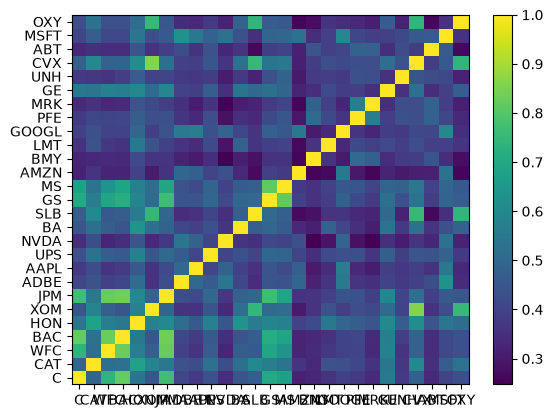

In [30]:
plt.figure()
plt.pcolor(corr)
plt.colorbar()
plt.yticks(np.arange(0.5, corr.shape[0] + 0.5), corr.columns)
plt.xticks(np.arange(0.5, corr.shape[0] + 0.5), corr.columns)


plt.show()

In [31]:
import numpy as np
import scipy.cluster.hierarchy as sch

def distance_corr(
        corr_matrix: np.ndarray
) -> np.ndarray:
    """
    Compute the distance matrix based on correlation.

    :param corr_matrix: Correlation matrix.
    :type corr_matrix: np.ndarray
    :return: Distance matrix based on correlation.
    :rtype: np.ndarray
    """
    distance_matrix = ((1 - corr_matrix) / 2.0) ** 0.5
    return distance_matrix



from sklearn.metrics import pairwise_distances

def distance_of_distances_df(corr_matrix: np.ndarray) -> pd.DataFrame:
    """
    Compute the 'distance of distances' matrix \tilde{D} from the distance DataFrame.
    The Euclidean distance is computed between the rows (or columns) of distance_df.

    :param distance_df: DataFrame containing the original distance matrix D.
    :return: DataFrame containing the second-level distance matrix \tilde{D},
             with index and columns matching those of distance_df.
    """
    # Compute the pairwise Euclidean distances using the underlying numpy array.
    distance_df = distance_corr(corr_matrix)
    d_values = pairwise_distances(distance_df.values, metric='euclidean')

    # Wrap the output back into a DataFrame
    d_tilde_df = pd.DataFrame(d_values, index=distance_df.index, columns=distance_df.index)
    return d_tilde_df



distance = distance_of_distances_df(corr)
link = sch.linkage(distance, 'single')

C:\Users\aghapour\AppData\Local\Temp\ipykernel_6448\2477081756.py:42: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  link = sch.linkage(distance, 'single')


In [32]:
link

array([[ 5.        , 23.        ,  0.53906249,  2.        ],
       [ 3.        ,  6.        ,  0.60209866,  2.        ],
       [ 2.        , 28.        ,  0.61311282,  3.        ],
       [13.        , 14.        ,  0.63686115,  2.        ],
       [ 0.        , 29.        ,  0.64312319,  4.        ],
       [12.        , 26.        ,  0.73812839,  2.        ],
       [27.        , 32.        ,  0.76137852,  4.        ],
       [30.        , 31.        ,  0.8077588 ,  6.        ],
       [ 1.        ,  4.        ,  0.84419167,  2.        ],
       [ 7.        , 25.        ,  0.87533655,  2.        ],
       [18.        , 36.        ,  0.91099218,  3.        ],
       [ 8.        , 37.        ,  0.94747703,  4.        ],
       [19.        , 20.        ,  0.95997552,  2.        ],
       [11.        , 35.        ,  0.96669888,  3.        ],
       [21.        , 40.        ,  0.96996797,  4.        ],
       [10.        , 38.        ,  1.00936639,  5.        ],
       [16.        , 39.

In [33]:
def quasi_diagonal(linkage_matrix: np.ndarray) -> list:
    """Return leaf indices in the order implied by the linkage tree."""
    linkage_matrix = linkage_matrix.astype(int)
    sorted_items = pd.Series([linkage_matrix[-1, 0], linkage_matrix[-1, 1]])
    num_items = linkage_matrix[-1, 3]

    while sorted_items.max() >= num_items:
        sorted_items.index = range(0, sorted_items.shape[0] * 2, 2)
        clusters = sorted_items[sorted_items >= num_items]
        left_positions = clusters.index
        linkage_rows = clusters.values - num_items

        sorted_items.loc[left_positions] = linkage_matrix[linkage_rows, 0]
        right_items = pd.Series(
            linkage_matrix[linkage_rows, 1],
            index=left_positions + 1,
        )
        sorted_items = pd.concat([sorted_items, right_items]).sort_index()
        sorted_items.index = range(sorted_items.shape[0])

    return sorted_items.tolist()


In [34]:
sortIx = quasi_diagonal(link)


In [35]:
sortIx = corr.index[sortIx].tolist()  # recover labels
dataframe = corr.loc[sortIx, sortIx]

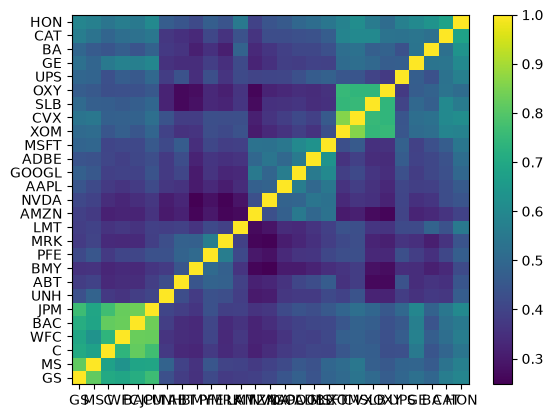

In [36]:
plt.figure()
plt.pcolor(dataframe)
plt.colorbar()
plt.yticks(np.arange(0.5, dataframe.shape[0] + 0.5), dataframe.columns)
plt.xticks(np.arange(0.5, dataframe.shape[0] + 0.5), dataframe.columns)


plt.show()

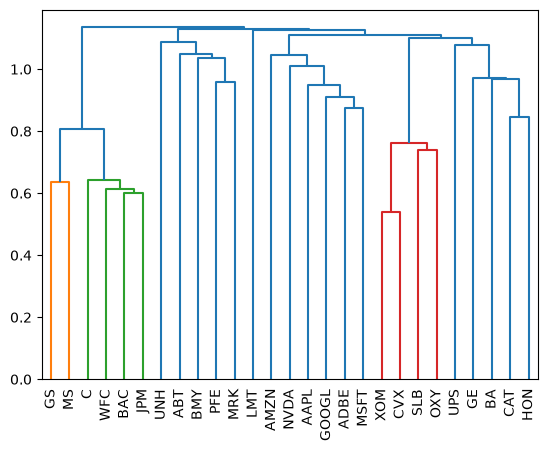

In [37]:
import matplotlib.pyplot as mpl

sch.dendrogram(link, labels=corr.index.tolist(), leaf_rotation=90)
mpl.show()


In [38]:
def inverse_variance_weights(covariance_matrix: pd.DataFrame) -> np.ndarray:
    """
    Compute the inverse-variance portfolio weights.

    :param covariance_matrix: Covariance matrix of asset returns.
    :type covariance_matrix: pd.DataFrame
    :return: Array of portfolio weights.
    :rtype: np.ndarray
    """
    inv_var_weights = 1.0 / np.diag(covariance_matrix)
    inv_var_weights /= inv_var_weights.sum()
    return inv_var_weights


def cluster_variance(covariance_matrix: pd.DataFrame, clustered_items: list) -> float:
    """
    Compute the variance of a cluster.

    :param covariance_matrix: Covariance matrix of asset returns.
    :type covariance_matrix: pd.DataFrame
    :param clustered_items: List of indices of assets in the cluster.
    :type clustered_items: list
    :return: Variance of the cluster.
    :rtype: float
    """
    cov_slice = covariance_matrix.loc[clustered_items, clustered_items]
    weights = inverse_variance_weights(cov_slice).reshape(-1, 1)
    cluster_variance = np.dot(np.dot(weights.T, cov_slice), weights)[0, 0]
    return cluster_variance

def recursive_bisection(covariance_matrix: pd.DataFrame, sorted_items: list) -> pd.Series:
    """
    Compute the Hierarchical Risk Parity (HRP) weights.

    :param covariance_matrix: Covariance matrix of asset returns.
    :type covariance_matrix: pd.DataFrame
    :param sorted_items: Sorted list of original items.
    :type sorted_items: list
    :return: DataFrame of asset weights.
    :rtype: pd.Series
    """
    weights = pd.Series(1.0, index=sorted_items)
    clustered_items = [sorted_items]

    while len(clustered_items) > 0:
        clustered_items = [
            i[j:k] for i in clustered_items for j, k in ((0, len(i) // 2), (len(i) // 2, len(i))) if len(i) > 1
        ]

        for i in range(0, len(clustered_items), 2):
            clustered_items_0 = clustered_items[i]

            clustered_items_1 = clustered_items[i + 1]

            cluster_variance_0 = cluster_variance(covariance_matrix, clustered_items_0)
            cluster_variance_1 = cluster_variance(covariance_matrix, clustered_items_1)
            alpha = 1 - cluster_variance_0 / (cluster_variance_0 + cluster_variance_1)
            weights.loc[clustered_items_0] *= alpha
            weights.loc[clustered_items_1] *= 1 - alpha

    return weights


In [39]:
weights = recursive_bisection(cov, sortIx)

In [40]:
weights

GS       0.030853
MS       0.009710
C        0.009114
WFC      0.023681
BAC      0.009766
JPM      0.016024
UNH      0.060959
ABT      0.085555
BMY      0.070836
PFE      0.065789
MRK      0.059525
LMT      0.083847
AMZN     0.030286
NVDA     0.022492
AAPL     0.033143
GOOGL    0.038657
ADBE     0.026790
MSFT     0.040182
XOM      0.037307
CVX      0.032389
SLB      0.029778
OXY      0.018030
UPS      0.060043
GE       0.023345
BA       0.021038
CAT      0.023901
HON      0.036959
dtype: float64

In [41]:
from scipy.optimize import minimize

def min_variance_portfolio_long_only(cov_matrix: pd.DataFrame) -> pd.Series:
    """Compute fully invested, long-only minimum-variance weights."""
    sigma = cov_matrix.to_numpy()
    n_assets = len(cov_matrix)

    # Rescaling improves numerical convergence but does not change the minimizer.
    scale = 1.0 / np.mean(np.diag(sigma))

    result = minimize(
        fun=lambda w: scale * (w @ sigma @ w),
        jac=lambda w: scale * (2.0 * sigma @ w),
        x0=np.full(n_assets, 1.0 / n_assets),
        method="SLSQP",
        bounds=[(0.0, 1.0)] * n_assets,
        constraints={
            "type": "eq",
            "fun": lambda w: w.sum() - 1.0,
            "jac": lambda w: np.ones(n_assets),
        },
        options={"ftol": 1e-12, "maxiter": 2000},
    )

    if not result.success:
        raise RuntimeError(f"Minimum-variance optimization failed: {result.message}")

    return pd.Series(
        result.x,
        index=cov_matrix.index,
        name="MinVarianceWeights",
    )


min_var_weights = min_variance_portfolio_long_only(cov)
min_var_variance = min_var_weights @ cov @ min_var_weights

print("Minimum Variance Portfolio Weights:")
print(min_var_weights.sort_values(ascending=False))
print(f"Portfolio variance: {min_var_variance:.10f}")


Minimum Variance Portfolio Weights:
Ticker
LMT      2.087778e-01
ABT      2.082335e-01
BMY      1.436185e-01
UPS      1.354189e-01
PFE      1.047846e-01
MRK      9.166648e-02
XOM      5.399026e-02
GOOGL    3.840659e-02
AAPL     1.510337e-02
HON      2.904653e-16
CVX      2.325233e-16
CAT      1.901540e-16
OXY      1.317690e-16
SLB      9.002738e-17
MSFT     8.810930e-17
GS       5.552489e-17
MS       5.277379e-17
JPM      3.560907e-17
ADBE     2.842768e-17
GE       1.356543e-17
BAC      1.025026e-17
C        0.000000e+00
WFC      0.000000e+00
NVDA     0.000000e+00
BA       0.000000e+00
AMZN     0.000000e+00
UNH      0.000000e+00
Name: MinVarianceWeights, dtype: float64
Portfolio variance: 0.0001134493


<Axes: >

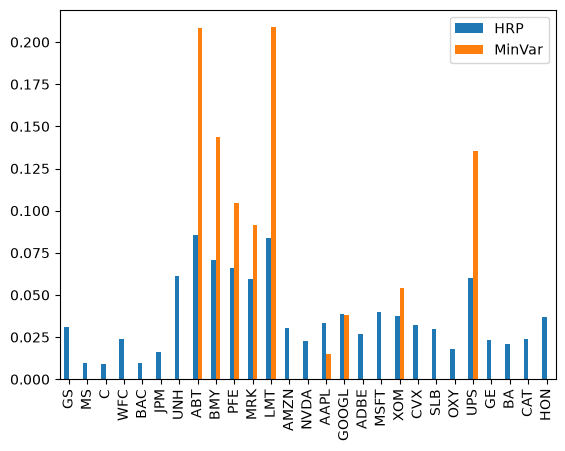

In [42]:
combine = pd.concat([weights, min_var_weights], axis=1)
combine.columns = ['HRP', 'MinVar']
combine.plot.bar()